# LightGBM quantile model (mFRR daily and weekly)

Same monthly walk-forward as the baseline and the Ridge. Before each test month, for each `freq × direction`
group, three LightGBM models (p10, p50, p90) are trained on every auction already published
(`src/models/lgbm.py`). The p50 is the prediction; p10 / p90 give the uncertainty.

- **Validation**: a validation period **before 2025**, to compare with the baseline and the Ridge.
- **Evaluation** (from 2025): produced once by `uv run python -m src.models.lgbm`, read at the end (section 7).

LightGBM trains 3 quantiles × 4 groups × 12 months, with the number of trees chosen on the last 3 months of
each training set.

In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from src.data.data import build_auctions
from src.evaluation import Evaluator
from src.features.build_features import add_model_features, build_features
from src.models import ridge
from src.models.baseline import PreviousKnownAuctionBaseline
from src.models.lgbm import lgbm_quantile_model, to_contract, walk_forward_lgbm

In [3]:
# team auction table (src/data/data.py), daily + weekly, KORR dropped (see ridge.prepare_auctions)
auctions_all = ridge.prepare_auctions(build_auctions(product="mFRR"), ("daily", "weekly"))
feats = add_model_features(build_features(auctions_all))     # lags + block / day-type one-hots
FEATURE_COLS = ridge.model_feature_columns(feats)

print("model inputs:", FEATURE_COLS)
feats.groupby(["freq", "direction"]).size()

model inputs: ['lag1', 'lag2', 'lag3', 'block_00_04', 'block_04_08', 'block_08_12', 'block_12_16', 'block_16_20', 'block_20_24', 'block_week', 'daytype_saturday', 'daytype_sunday_holiday', 'daytype_week', 'daytype_workday']


freq    direction
daily   downwards    17040
        upwards      17034
weekly  downwards      410
        upwards        410
dtype: int64

## 1. Validation period

Same choice as in `ridge.ipynb`: a period before 2025 whose daily auctions have prices.

In [4]:
a = auctions_all.copy()
a["year"] = a["gc"].dt.year
a.pivot_table(index="year", columns=["freq", "direction"], values="y",
              aggfunc=lambda y: y.isna().mean()).round(2)

freq          daily            weekly        
direction downwards upwards downwards upwards
year                                         
2018           0.00    0.00       NaN     NaN
2019           0.05    0.00       0.0     0.0
2020           0.00    0.06       0.0     0.0
2021           0.11    0.06       0.0     0.0
2022           0.16    0.10       0.0     0.0
2023           0.19    0.12       0.0     0.0
2024           0.90    0.83       0.0     0.0
2025           0.00    0.00       0.0     0.0
2026           0.03    0.00       0.0     0.0

In [5]:
VAL_START, VAL_LAST_DAY = "2024-01-01", "2024-12-31"
VAL_END = (pd.Timestamp(VAL_LAST_DAY) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # exclusive end, for the Evaluator

in_val = (auctions_all["gc"] >= pd.Timestamp(VAL_START, tz="UTC")) & (auctions_all["gc"] < pd.Timestamp(VAL_END, tz="UTC"))
print(VAL_START, "to", VAL_LAST_DAY, ":", in_val.sum(), "auctions,", auctions_all.loc[in_val, "y"].notna().sum(), "with a price")

2024-01-01 to 2024-12-31 : 4120 auctions, 646 with a price


## 2. Walk-forward on the validation period

LightGBM with the default target `delta` = y − lag1.

In [6]:
preds_lgbm = walk_forward_lgbm(feats, start_test=VAL_START, end_test=VAL_LAST_DAY, feature_cols=FEATURE_COLS)
print(len(preds_lgbm), "auctions predicted")

4120 auctions predicted


In [7]:
RIDGE_VARIANT = "ridge_allfeats_delta"      # the best variant of ridge.ipynb
ridge_variants = {
    "ridge_lags3":          dict(feature_cols=ridge.FEATURES, target="level"),
    "ridge_lags3_delta":    dict(feature_cols=ridge.FEATURES, target="delta"),
    "ridge_allfeats_delta": dict(feature_cols=FEATURE_COLS, target="delta"),
    "ridge_lags3_delta_per_series": dict(feature_cols=ridge.FEATURES, target="delta", group_cols=["series"]),
}
preds_ridge = ridge.walk_forward_ridge(feats, start_test=VAL_START, end_test=VAL_LAST_DAY, **ridge_variants[RIDGE_VARIANT])

## 3. The four groups: LightGBM vs Ridge vs baseline

In [8]:
baseline = PreviousKnownAuctionBaseline().fit(auctions_all)
contracts = {
    "baseline": baseline.predict(auctions_all[in_val]),
    RIDGE_VARIANT: ridge.to_contract(preds_ridge, RIDGE_VARIANT),
    "lgbm_quantile": to_contract(preds_lgbm),
}
evaluator = Evaluator(actuals=auctions_all, start_test=VAL_START, end_test=VAL_END)
report = evaluator.evaluate_many(contracts)

report.pivot_table(index=["freq", "direction"], columns="model", values="mae").round(3)

model             baseline  lgbm_quantile  ridge_allfeats_delta
freq   direction                                               
daily  downwards     0.253          0.231                 0.243
       upwards       0.293          0.246                 0.271
weekly downwards     0.126          0.120                 0.127
       upwards       0.046          0.043                 0.044

In [9]:
# full report: n, MAE, RMSE, pinball of each quantile and coverage of [p10, p90] (ideal 0.80)
cols = [c for c in ["model", "freq", "direction", "n", "mae", "rmse", "pinball_q10", "pinball_q50", "pinball_q90", "coverage_80"]
        if c in report.columns]
report[cols].sort_values(["freq", "direction", "model"]).round(3)

,model,freq,direction,n,mae,rmse,pinball_q10,pinball_q50,pinball_q90,coverage_80
0,baseline,daily,downwards,192,0.253,0.438,None,None,None,None
8,lgbm_quantile,daily,downwards,192,0.231,0.444,0.05651,0.115253,0.09308,0.796875
4,ridge_allfeats_delta,daily,downwards,192,0.243,0.429,0.054506,0.121514,0.103124,0.859375
1,baseline,daily,upwards,348,0.293,0.455,None,None,None,None
9,lgbm_quantile,daily,upwards,348,0.246,0.371,0.050549,0.122828,0.064474,0.704023
5,ridge_allfeats_delta,daily,upwards,348,0.271,0.363,0.057181,0.135604,0.075183,0.821839
2,baseline,weekly,downwards,53,0.126,0.210,None,None,None,None
10,lgbm_quantile,weekly,downwards,53,0.120,0.213,0.034273,0.060047,0.052989,0.622642
6,ridge_allfeats_delta,weekly,downwards,53,0.127,0.202,0.029868,0.063334,0.050583,0.716981
3,baseline,weekly,upwards,53,0.046,0.074,None,None,None,None


In [10]:
rows = {}
for name, p, col in [("baseline", preds_lgbm, "pred_baseline"), (RIDGE_VARIANT, preds_ridge, "pred_ridge"),
                     ("lgbm_quantile", preds_lgbm, "pred_lgbm")]:
    s = p[p["y"].notna()]
    rows[name] = (s[col] - s["y"]).abs().groupby([s["gc"].dt.year, s["freq"], s["direction"]]).mean()
pd.DataFrame(rows).round(3)

baseline  ridge_allfeats_delta  lgbm_quantile
gc   freq   direction                                               
2024 daily  downwards     0.253                 0.243          0.231
            upwards       0.293                 0.271          0.246
     weekly downwards     0.126                 0.127          0.120
            upwards       0.046                 0.044          0.043

## 3. Number of trees chosen

For each month, group and quantile, `walk_forward_lgbm` chooses the number of trees on the last 3 months of the
training data (time-only validation). Weekly groups have little history: they often fall back to the first value.

In [10]:
tuning = preds_lgbm.attrs["tuning"]
tuning.groupby(["freq", "direction", "quantile"])["n_estimators"].value_counts().unstack(fill_value=0)

n_estimators               100  300  600
freq   direction quantile               
daily  downwards 0.1         1    0   11
                 0.5        12    0    0
                 0.9         1    0   11
       upwards   0.1         1    9    2
                 0.5         1    2    9
                 0.9         1   10    1
weekly downwards 0.1        12    0    0
                 0.5        12    0    0
                 0.9        12    0    0
       upwards   0.1        12    0    0
                 0.5        12    0    0
                 0.9        12    0    0

## 4. Which features does LightGBM use?

One p50 model per group, trained on everything published before the validation period. Importance = number of
times a feature is used in a split.

In [11]:
importance = {}
before = feats[feats["avail"] < VAL_START].dropna(subset=["y", "lag1"])
for (freq, direction), d in before.groupby(["freq", "direction"]):
    model = lgbm_quantile_model(0.5, 300).fit(d[FEATURE_COLS], d["y"] - d["lag1"])
    importance[f"{freq} {direction}"] = pd.Series(model.feature_importances_, index=FEATURE_COLS)

pd.DataFrame(importance).sort_values("daily downwards", ascending=False)

,daily downwards,daily upwards,weekly downwards,weekly upwards
lag1,1230,1199,106,94
lag3,1228,1310,273,290
lag2,1211,1153,264,258
daytype_workday,108,103,0,0
block_00_04,74,121,0,0
block_04_08,66,34,0,0
block_08_12,55,45,0,0
block_12_16,55,66,0,0
daytype_sunday_holiday,50,45,0,0
daytype_saturday,48,42,0,0


## 5. Quantiles and bidding

Pay-as-bid: a bid is accepted only if it is **at or below** the marginal price.
- `share_below_p10`: how often the actual price fell below the p10 (ideal ≈ 0.10);
- `share_rejected` / `revenue_share`: bidding always at that price, share of rejected bids and revenue as a
  share of perfect foresight (simplified: small bidder, paid its own price, does not move the market).

In [12]:
p = preds_lgbm[preds_lgbm["y"].notna()]
groups = [p["freq"], p["direction"]]

calibration = pd.DataFrame({
    "coverage_p10_p90": ((p["y"] >= p["p10_lgbm"]) & (p["y"] <= p["p90_lgbm"])).groupby(groups).mean(),
    "share_below_p10": (p["y"] < p["p10_lgbm"]).groupby(groups).mean(),
    "share_above_p90": (p["y"] > p["p90_lgbm"]).groupby(groups).mean(),
    "mean_width_p10_p90": (p["p90_lgbm"] - p["p10_lgbm"]).groupby(groups).mean(),
})
calibration.round(3)

coverage_p10_p90  share_below_p10  share_above_p90  \
freq   direction                                                       
daily  downwards             0.797            0.115            0.089   
       upwards               0.704            0.089            0.207   
weekly downwards             0.623            0.245            0.132   
       upwards               0.717            0.208            0.075   

                  mean_width_p10_p90  
freq   direction                      
daily  downwards               0.556  
       upwards                 0.641  
weekly downwards               0.226  
       upwards                 0.138

In [13]:
bids = {"baseline (lag1)": "pred_baseline", "lgbm p50": "p50_lgbm", "lgbm p10": "p10_lgbm"}
perfect = (10 ** p["y"]).groupby(groups).sum()
rows = {}
for name, col in bids.items():
    accepted = p[col] <= p["y"]
    revenue = (10 ** p[col]).where(accepted, 0.0)
    rows[(name, "share_rejected")] = (~accepted).groupby(groups).mean()
    rows[(name, "revenue_share")] = revenue.groupby(groups).sum() / perfect
pd.DataFrame(rows).T.round(3)

freq                               daily            weekly        
direction                      downwards upwards downwards upwards
baseline (lag1) share_rejected     0.573   0.580     0.774   0.717
                revenue_share      0.444   0.232     0.170   0.276
lgbm p50        share_rejected     0.495   0.356     0.717   0.585
                revenue_share      0.612   0.358     0.220   0.373
lgbm p10        share_rejected     0.115   0.089     0.245   0.208
                revenue_share      0.416   0.357     0.545   0.731

## 6. One series, one month

Actual price, baseline and LightGBM p50 with the p10–p90 band. Gaps in the black line are no-buy auctions.

31 auctions, 7 without a price


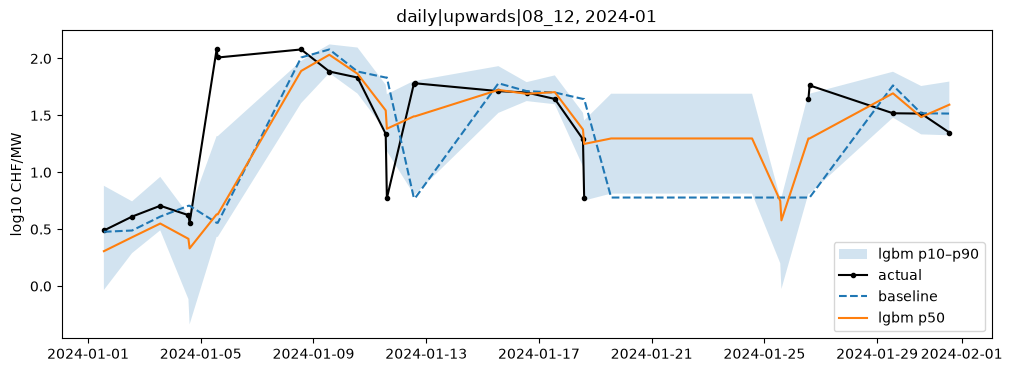

In [14]:
SERIES = "daily|upwards|08_12"
MONTH = VAL_START[:7]

start = pd.Timestamp(MONTH, tz="UTC")
end = start + pd.offsets.MonthBegin(1)
s = preds_lgbm[(preds_lgbm["series"] == SERIES) & (preds_lgbm["gc"] >= start) & (preds_lgbm["gc"] < end)]
print(len(s), "auctions,", s["y"].isna().sum(), "without a price")

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(s["gc"], s["p10_lgbm"], s["p90_lgbm"], alpha=0.2, label="lgbm p10–p90")
ax.plot(s["gc"], s["y"], "k.-", label="actual")
ax.plot(s["gc"], s["pred_baseline"], "--", label="baseline")
ax.plot(s["gc"], s["p50_lgbm"], "-", label="lgbm p50")
ax.set_ylabel("log10 CHF/MW")
ax.set_title(f"{SERIES}, {MONTH}")
ax.legend()
plt.show()

## 7. Final result on the test period (2025 →)

Read from the files written by `uv run python -m src.models.baseline`, `... src.models.ridge` and
`... src.models.lgbm`. Do not use these numbers to change the models.

In [15]:
RESULTS = Path("../results")
files = sorted(RESULTS.glob("metrics_*.parquet"))
if files:
    final = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
    display(final.pivot_table(index=["freq", "direction"], columns="model", values="mae").round(3))
    if "coverage_80" in final:
        display(final.pivot_table(index=["freq", "direction"], columns="model", values="coverage_80").round(3))
else:
    print("no metrics_*.parquet in results/: run the baseline, ridge and lgbm scripts first")

no metrics_*.parquet in results/: run the baseline, ridge and lgbm scripts first
